# Employment Trends in AI, Data Science and Software Development

## Introduction
This research looks into employment trends in software development, data science, and artificial intelligence (AI) fields in the US.

The U.S. Bureau of Labor Statistics (BLS) Occupational Employment and Wage Statistics (OEWS) datasets for 2022, 2023, 2024, and 2025 are used in the research.

The data is prepared, analyzed, and visualized using Python modules such as Pandas, NumPy, Matplotlib, and Seaborn.

This study aims to determine employment patterns over time, analyze annual salary disparities, and compare employment levels across technology-related occupations.

**Scope:** The chosen professions have to do with artificial intelligence and the technologies that support it. The number of persons working specifically in AI is not directly measured by the datasets.

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully!")


Libraries imported successfully!


## Data Sources and Preparation
The employment data used in this project was obtained from the U.S. Bureau of Labor Statistics (BLS) Occupational Employment and Wage Statistics (OEWS) programme.

The datasets cover the years 2022, 2023, 2024 and 2025. They contain information about occupational employment estimates, occupation titles, industry classifications and annual wage estimates.

The data will be inspected and prepared using Pandas before being used to create visualisations.

The 2023 dataset contains a larger number of records than the other years. Therefore, the relevant national employment records will be selected to ensure that comparisons across years are consistent.

**Source:** U.S. Bureau of Labor Statistics. Occupational Employment and Wage Statistics. https://www.bls.gov/oes/tables.htm

In [7]:
# Inspect the national records in each dataset

for year, df in {
    2022: data_2022,
    2023: data_2023,
    2024: data_2024,
    2025: data_2025
}.items():
    print(f"\n{year}")
    print(df["AREA_TITLE"].value_counts().head())


2022
AREA_TITLE
U.S.    1402
Name: count, dtype: int64

2023
AREA_TITLE
U.S.            177501
California         836
Texas              830
Pennsylvania       814
Michigan           813
Name: count, dtype: int64

2024
AREA_TITLE
U.S.    1403
Name: count, dtype: int64

2025
AREA_TITLE
U.S.    1401
Name: count, dtype: int64


In [12]:
# Organise the four datasets

datasets = {
    2022: data_2022,
    2023: data_2023,
    2024: data_2024,
    2025: data_2025
}

# Filter all datasets to national U.S. records

national_datasets = {}

for year, df in datasets.items():

    national_datasets[year] = df[
        df["AREA_TITLE"] == "U.S."
    ].copy()

    print(
        year,
        "National records:",
        len(national_datasets[year])
    )

2022 National records: 1402
2023 National records: 177501
2024 National records: 1403
2025 National records: 1401


In [13]:
# Select three technology-related occupations

selected_occupations = [
    "15-1212",  # Information Security Analysts
    "15-1252",  # Software Developers
    "15-2051"   # Data Scientists
]

for year, df in national_datasets.items():

    print(f"\n--- {year} ---")

    results = df[
        df["OCC_CODE"].isin(selected_occupations)
    ][["OCC_CODE", "OCC_TITLE"]].drop_duplicates()

    print(results.to_string(index=False))


--- 2022 ---
OCC_CODE                     OCC_TITLE
 15-1212 Information Security Analysts
 15-1252           Software Developers
 15-2051               Data Scientists

--- 2023 ---
OCC_CODE                     OCC_TITLE
 15-1212 Information Security Analysts
 15-1252           Software Developers
 15-2051               Data Scientists

--- 2024 ---
OCC_CODE                     OCC_TITLE
 15-1212 Information Security Analysts
 15-1252           Software Developers
 15-2051               Data Scientists

--- 2025 ---
OCC_CODE                     OCC_TITLE
 15-1212 Information Security Analysts
 15-1252           Software Developers
 15-2051               Data Scientists


In [14]:
# Build a combined employment and wage dataset

comparison_data = []

for year, df in national_datasets.items():

    selected = df[
        df["OCC_CODE"].isin(selected_occupations)
    ].copy()

    for _, row in selected.iterrows():

        comparison_data.append({
            "Year": year,
            "Occupation": row["OCC_TITLE"],
            "Occupation_Code": row["OCC_CODE"],
            "Employment": row["TOT_EMP"],
            "Median_Annual_Wage": pd.to_numeric(
                row["A_MEDIAN"], errors="coerce"
            )
        })

comparison_df = pd.DataFrame(comparison_data)

comparison_df

,Year,Occupation,Occupation_Code,Employment,Median_Annual_Wage
0,2022,Information Security Analysts,15-1212,163690,112000.0
1,2022,Software Developers,15-1252,1534790,127260.0
2,2022,Data Scientists,15-2051,159630,103500.0
3,2023,Information Security Analysts,15-1212,175350,120360.0
4,2023,Software Developers,15-1252,1656880,132270.0
...,...,...,...,...,...
893,2024,Software Developers,15-1252,1654440,133080.0
894,2024,Data Scientists,15-2051,233440,112590.0
895,2025,Information Security Analysts,15-1212,190650,129180.0
896,2025,Software Developers,15-1252,1687890,135980.0


In [32]:
# Check the number of records for each year
print("Records per year:")
print(comparison_df["Year"].value_counts().sort_index())

# Check the occupations included
print("\nOccupations included:")
print(comparison_df["Occupation"].value_counts())

# Check the unique occupation and year combinations
print("\nYear and occupation combinations:")
print(
    comparison_df.groupby(["Year", "Occupation"]).size()
)

Records per year:
Year
2022    3
2023    3
2024    3
2025    3
Name: count, dtype: int64

Occupations included:
Occupation
Information Security Analysts    4
Software Developers              4
Data Scientists                  4
Name: count, dtype: int64

Year and occupation combinations:
Year  Occupation                   
2022  Data Scientists                  1
      Information Security Analysts    1
      Software Developers              1
2023  Data Scientists                  1
      Information Security Analysts    1
      Software Developers              1
2024  Data Scientists                  1
      Information Security Analysts    1
      Software Developers              1
2025  Data Scientists                  1
      Information Security Analysts    1
      Software Developers              1
dtype: int64


In [15]:
# Check the completed comparison dataset

print("Number of records:", len(comparison_df))
print("\nMissing values:")
print(comparison_df.isnull().sum())

print("\nDataset information:")
comparison_df.info()

Number of records: 898

Missing values:
Year                  0
Occupation            0
Occupation_Code       0
Employment            0
Median_Annual_Wage    7
dtype: int64

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 898 entries, 0 to 897
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Year                898 non-null    int64  
 1   Occupation          898 non-null    str    
 2   Occupation_Code     898 non-null    str    
 3   Employment          898 non-null    object 
 4   Median_Annual_Wage  891 non-null    float64
dtypes: float64(1), int64(1), object(1), str(2)
memory usage: 59.2+ KB


In [35]:
print("Records per year:")
print(comparison_df["Year"].value_counts().sort_index())

print("\nOccupations included:")
print(comparison_df["Occupation"].value_counts())

print("\nRecords per year and occupation:")
print(comparison_df.groupby(["Year", "Occupation"]).size())

Records per year:
Year
2022    3
2023    3
2024    3
2025    3
Name: count, dtype: int64

Occupations included:
Occupation
Information Security Analysts    4
Software Developers              4
Data Scientists                  4
Name: count, dtype: int64

Records per year and occupation:
Year  Occupation                   
2022  Data Scientists                  1
      Information Security Analysts    1
      Software Developers              1
2023  Data Scientists                  1
      Information Security Analysts    1
      Software Developers              1
2024  Data Scientists                  1
      Information Security Analysts    1
      Software Developers              1
2025  Data Scientists                  1
      Information Security Analysts    1
      Software Developers              1
dtype: int64


In [36]:
# Display all records in the comparison dataset
print(comparison_df.to_string(index=False))

# Identify missing wage values
print("\nRecords with missing wages:")
print(
    comparison_df[
        comparison_df["Median_Annual_Wage"].isna()
    ].to_string(index=False)
)

# Check for duplicate year and occupation combinations
print("\nDuplicate records:")
print(
    comparison_df[
        comparison_df.duplicated(
            subset=["Year", "Occupation"],
            keep=False
        )
    ]
)

 Year                    Occupation Occupation_Code  Employment  Median_Annual_Wage
 2022 Information Security Analysts         15-1212      163690              112000
 2022           Software Developers         15-1252     1534790              127260
 2022               Data Scientists         15-2051      159630              103500
 2023 Information Security Analysts         15-1212      175350              120360
 2023           Software Developers         15-1252     1656880              132270
 2023               Data Scientists         15-2051      192710              108020
 2024 Information Security Analysts         15-1212      179430              124910
 2024           Software Developers         15-1252     1654440              133080
 2024               Data Scientists         15-2051      233440              112590
 2025 Information Security Analysts         15-1212      190650              129180
 2025           Software Developers         15-1252     1687890             

In [37]:
# Calculate employment growth between 2022 and 2025

employment_pivot = comparison_df.pivot(
    index="Occupation",
    columns="Year",
    values="Employment"
)

employment_growth = pd.DataFrame()

employment_growth["Employment_2022"] = employment_pivot[2022]
employment_growth["Employment_2025"] = employment_pivot[2025]

employment_growth["Employment_Increase"] = (
    employment_growth["Employment_2025"]
    - employment_growth["Employment_2022"]
)

employment_growth["Growth_Percentage"] = (
    employment_growth["Employment_Increase"]
    / employment_growth["Employment_2022"]
) * 100

employment_growth = employment_growth.round(2)

print("Employment Growth by Occupation (2022–2025)")
display(employment_growth)

Employment Growth by Occupation (2022–2025)


,Employment_2022,Employment_2025,Employment_Increase,Growth_Percentage
Occupation,,,,
Data Scientists,159630,262440,102810,64.41
Information Security Analysts,163690,190650,26960,16.47
Software Developers,1534790,1687890,153100,9.98


In [38]:
# Calculate median annual wage growth (2022–2025)

wage_pivot = comparison_df.pivot(
    index="Occupation",
    columns="Year",
    values="Median_Annual_Wage"
)

wage_growth = pd.DataFrame()

wage_growth["Wage_2022"] = wage_pivot[2022]
wage_growth["Wage_2025"] = wage_pivot[2025]

wage_growth["Wage_Increase"] = (
    wage_growth["Wage_2025"]
    - wage_growth["Wage_2022"]
)

wage_growth["Growth_Percentage"] = (
    wage_growth["Wage_Increase"]
    / wage_growth["Wage_2022"]
) * 100

wage_growth = wage_growth.round(2)

print("Median Annual Wage Growth (2022–2025)")
display(wage_growth)

Median Annual Wage Growth (2022–2025)


,Wage_2022,Wage_2025,Wage_Increase,Growth_Percentage
Occupation,,,,
Data Scientists,103500,120230,16730,16.16
Information Security Analysts,112000,129180,17180,15.34
Software Developers,127260,135980,8720,6.85


Employment vs Wage Growth (2022–2025)


,Employment Growth (%),Wage Growth (%)
Occupation,,
Data Scientists,64.41,16.16
Information Security Analysts,16.47,15.34
Software Developers,9.98,6.85


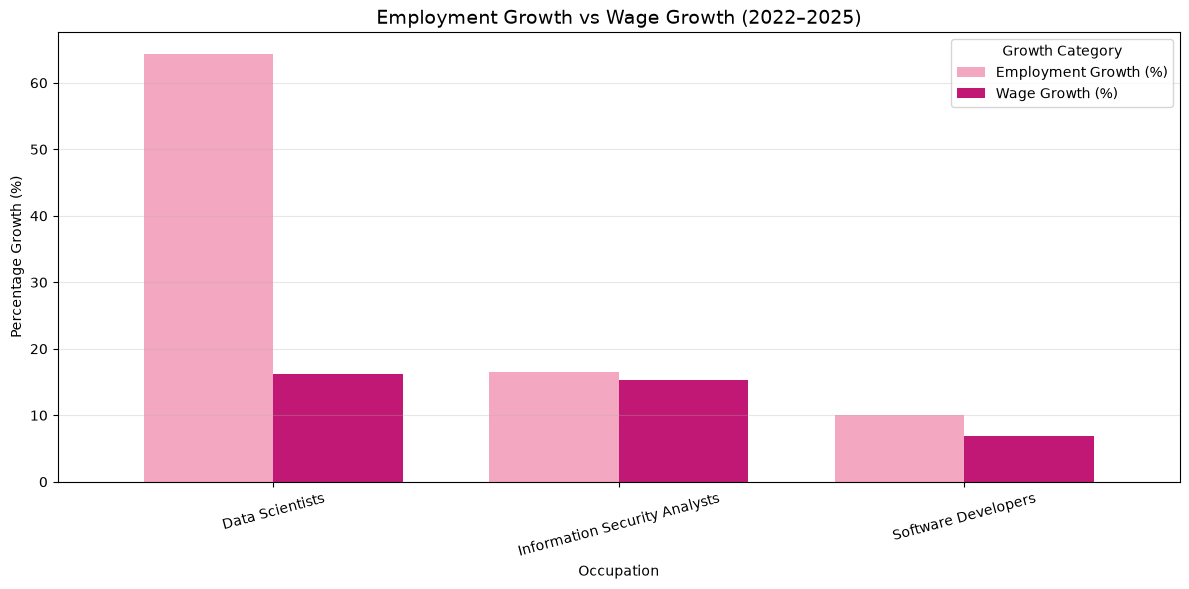

In [39]:
# Combine employment and wage growth results

growth_comparison = pd.DataFrame({
    "Employment Growth (%)": employment_growth["Growth_Percentage"],
    "Wage Growth (%)": wage_growth["Growth_Percentage"]
})

print("Employment vs Wage Growth (2022–2025)")
display(growth_comparison)

# Create a grouped bar chart
ax = growth_comparison.plot(
    kind="bar",
    figsize=(12, 6),
    color=["#F4A7C0", "#C21875"],
    width=0.75
)

plt.title(
    "Employment Growth vs Wage Growth (2022–2025)",
    fontsize=14
)
plt.xlabel("Occupation")
plt.ylabel("Percentage Growth (%)")
plt.xticks(rotation=15)
plt.legend(title="Growth Category")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [40]:
# Explore the relationship between employment and median wages

correlation = comparison_df[
    ["Employment", "Median_Annual_Wage"]
].corr()

print("Employment and Wage Correlation Matrix:")
display(correlation)

# Calculate the overall Pearson correlation
overall_correlation = comparison_df[
    "Employment"
].corr(comparison_df["Median_Annual_Wage"])

print(
    "\nOverall Pearson correlation:",
    round(overall_correlation, 3)
)

# Calculate correlation separately for each occupation
print("\nCorrelation by Occupation:")

for occupation, group in comparison_df.groupby("Occupation"):
    occupation_corr = group["Employment"].corr(
        group["Median_Annual_Wage"]
    )

    print(occupation, ":", round(occupation_corr, 3))

Employment and Wage Correlation Matrix:


,Employment,Median_Annual_Wage
Employment,1.000000,0.744799
Median_Annual_Wage,0.744799,1.000000



Overall Pearson correlation: 0.745

Correlation by Occupation:
Data Scientists : 0.982
Information Security Analysts : 0.983
Software Developers : 0.971


## Correlation Analysis: Employment and Median Annual Wages

Pearson correlation analysis was conducted to investigate the connection between employment rates and median yearly wages in the three chosen professions.
The merged dataset yielded a positive correlation coefficient of 0.745, signifying a positive relationship between employment and median yearly wages across the 12 observations.
When analyzed individually, the careers generated correlation coefficients of 0.982 for Data Scientists, 0.983 for Information Security Analysts, and 0.971 for Software Developers.
These findings indicate that employment and average yearly wages typically rose in tandem during the analyzed timeframe.
Nonetheless, the correlations specific to occupations rely on just four yearly observations for each. The outcomes might be affected by the common upward trends in employment and wages over time. Correlation does not prove causation, and a more extensive dataset would be required for a more reliable investigation of this relationship.
Consequently, the results should be viewed as preliminary evidence of a connection instead of definitive proof that increased employment rates result in higher wages.


In [16]:
# Investigate duplicate occupation records

for year, df in national_datasets.items():

    selected = df[
        df["OCC_CODE"].isin(selected_occupations)
    ]

    print(f"\n--- {year} ---")

    print("NAICS values:")
    print(selected["NAICS"].value_counts().head(10))

    print("\nOwnership values:")
    print(selected["OWN_CODE"].value_counts())

    print("\nIndustry titles:")
    print(selected["NAICS_TITLE"].value_counts().head(10))


--- 2022 ---
NAICS values:
NAICS
0    3
Name: count, dtype: int64

Ownership values:
OWN_CODE
1235    3
Name: count, dtype: int64

Industry titles:
NAICS_TITLE
Cross-industry    3
Name: count, dtype: int64

--- 2023 ---
NAICS values:
NAICS
611000    12
622000    12
622100    12
611300    11
611200     9
611100     8
611700     8
611500     7
622300     7
455000     6
Name: count, dtype: int64

Ownership values:
OWN_CODE
5       754
235      37
3        26
2        23
57       21
1        10
123       9
1235      3
58        3
59        3
Name: count, dtype: int64

Industry titles:
NAICS_TITLE
Educational Services                                            15
Hospitals                                                       12
General Medical and Surgical Hospitals                          12
Colleges, Universities, and Professional Schools                11
Management of Companies and Enterprises                          9
Junior Colleges                                                 

In [17]:
# Filter national, cross-industry, all-ownership records

clean_datasets = {}

for year, df in datasets.items():

    filtered = df[
        (df["AREA_TITLE"] == "U.S.") &
        (df["NAICS"] == 0) &
        (df["OWN_CODE"] == 1235) &
        (df["OCC_CODE"].isin(selected_occupations))
    ].copy()

    clean_datasets[year] = filtered

    print(f"{year}: {len(filtered)} records")

    print(
        filtered[["OCC_CODE", "OCC_TITLE"]].to_string(index=False)
    )

2022: 3 records
OCC_CODE                     OCC_TITLE
 15-1212 Information Security Analysts
 15-1252           Software Developers
 15-2051               Data Scientists
2023: 0 records
Empty DataFrame
Columns: [OCC_CODE, OCC_TITLE]
Index: []
2024: 3 records
OCC_CODE                     OCC_TITLE
 15-1212 Information Security Analysts
 15-1252           Software Developers
 15-2051               Data Scientists
2025: 3 records
OCC_CODE                     OCC_TITLE
 15-1212 Information Security Analysts
 15-1252           Software Developers
 15-2051               Data Scientists


In [18]:
# Inspect the 2023 records for our selected occupations

check_2023 = data_2023[
    (data_2023["AREA_TITLE"] == "U.S.") &
    (data_2023["OCC_CODE"].isin(selected_occupations))
].copy()

# Show the three all-ownership records and their industry codes

print(
    check_2023[
        check_2023["OWN_CODE"] == 1235
    ][
        ["AREA_TITLE", "NAICS", "NAICS_TITLE",
         "OWN_CODE", "OCC_CODE", "OCC_TITLE",
         "TOT_EMP", "A_MEDIAN"]
    ].to_string(index=False)
)

AREA_TITLE  NAICS    NAICS_TITLE  OWN_CODE OCC_CODE                     OCC_TITLE TOT_EMP A_MEDIAN
      U.S. 000000 Cross-industry      1235  15-1212 Information Security Analysts  175350   120360
      U.S. 000000 Cross-industry      1235  15-1252           Software Developers 1656880   132270
      U.S. 000000 Cross-industry      1235  15-2051               Data Scientists  192710   108020


In [19]:
# Standardise NAICS codes and filter the national records

clean_datasets = {}

for year, df in datasets.items():

    df = df.copy()

    # Convert NAICS codes to six-character text
    df["NAICS_CLEAN"] = (
        df["NAICS"].astype(str).str.zfill(6)
    )

    filtered = df[
        (df["AREA_TITLE"] == "U.S.") &
        (df["NAICS_CLEAN"] == "000000") &
        (df["OWN_CODE"] == 1235) &
        (df["OCC_CODE"].isin(selected_occupations))
    ].copy()

    clean_datasets[year] = filtered

    print(f"{year}: {len(filtered)} records")

2022: 3 records
2023: 3 records
2024: 3 records
2025: 3 records


In [20]:
# Combine the cleaned records into one comparison table

comparison_data = []

for year, df in clean_datasets.items():

    for _, row in df.iterrows():

        comparison_data.append({
            "Year": year,
            "Occupation": row["OCC_TITLE"],
            "Occupation_Code": row["OCC_CODE"],
            "Employment": pd.to_numeric(
                row["TOT_EMP"], errors="coerce"
            ),
            "Median_Annual_Wage": pd.to_numeric(
                row["A_MEDIAN"], errors="coerce"
            )
        })

comparison_df = pd.DataFrame(comparison_data)

print("Total records:", len(comparison_df))

comparison_df

Total records: 12


,Year,Occupation,Occupation_Code,Employment,Median_Annual_Wage
0,2022,Information Security Analysts,15-1212,163690,112000
1,2022,Software Developers,15-1252,1534790,127260
2,2022,Data Scientists,15-2051,159630,103500
3,2023,Information Security Analysts,15-1212,175350,120360
4,2023,Software Developers,15-1252,1656880,132270
5,2023,Data Scientists,15-2051,192710,108020
6,2024,Information Security Analysts,15-1212,179430,124910
7,2024,Software Developers,15-1252,1654440,133080
8,2024,Data Scientists,15-2051,233440,112590
9,2025,Information Security Analysts,15-1212,190650,129180


## Visualisation 1: Employment Trends Over Time

### Objective
The objective of this visualisation is to investigate how employment levels have changed between 2022 and 2025 across Information Security Analysts, Software Developers and Data Scientists.

### Visualisation choice
A line chart was selected because it clearly displays changes over time. It allows trends across multiple occupations to be compared using a consistent time scale.A logarithmic scale was employed on the y-axis due to the significant variation in employment numbers across different occupations. This facilitates the observation of changes in the smaller employment groups.


### Findings
The data shows that employment increased across all three occupations between 2022 and 2025. Software Developers had the highest employment throughout the period, while Information Security Analysts and Data Scientists had smaller employment totals.

This visualisation highlights the continued demand for technology-related occupations.

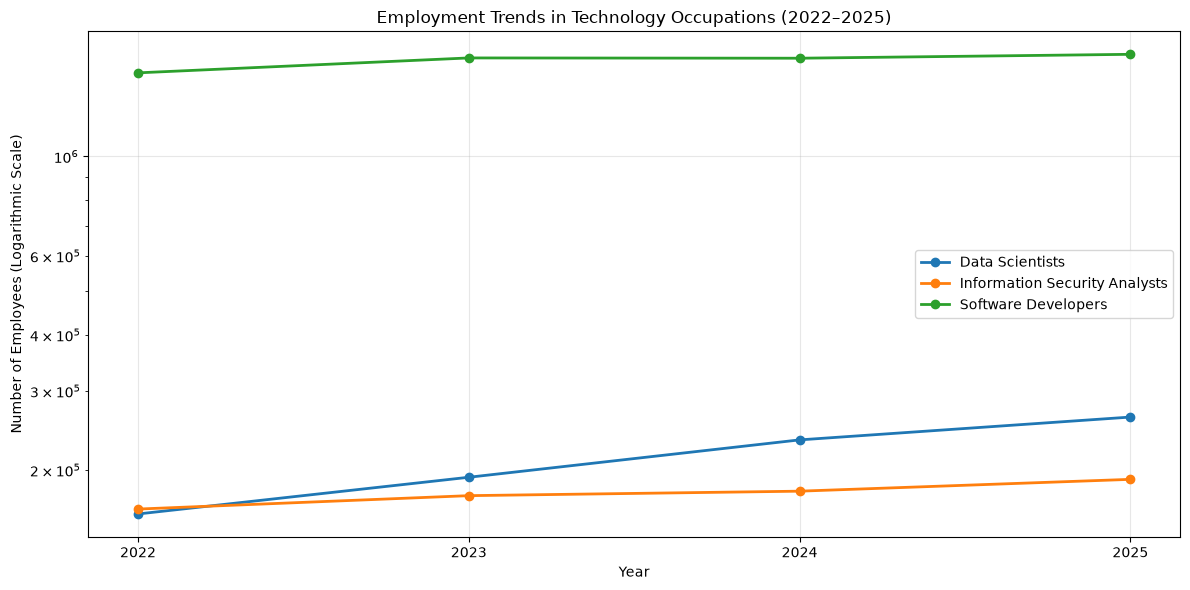

In [22]:
# Visualisation 1: Employment trends over time

employment_pivot = comparison_df.pivot(
    index="Year",
    columns="Occupation",
    values="Employment"
)

plt.figure(figsize=(12, 6))

for occupation in employment_pivot.columns:
    plt.plot(
        employment_pivot.index,
        employment_pivot[occupation],
        marker="o",
        linewidth=2,
        label=occupation
    )

plt.yscale("log")

plt.title("Employment Trends in Technology Occupations (2022–2025)")
plt.xlabel("Year")
plt.ylabel("Number of Employees (Logarithmic Scale)")
plt.xticks([2022, 2023, 2024, 2025])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Visualisation 2: Employment Comparison by Occupation in 2025

### Objective
This visualisation aims to compare employment rates for Information Security Analysts, Software Developers, and Data Scientists in 2025.

### Visualisation choice
A horizontal bar chart was chosen as it facilitates the comparison of numerical values among various occupational categories. It enables the clear display of longer job titles

### Results 
In 2025, Software Developers reached the highest employment figure, totaling 1,687,890 workers. Data Scientists employed 262,440 individuals, whereas Information Security Analysts had 190,650 individuals.The findings indicate that software development offers a significantly greater employment foundation compared to the other two fields.

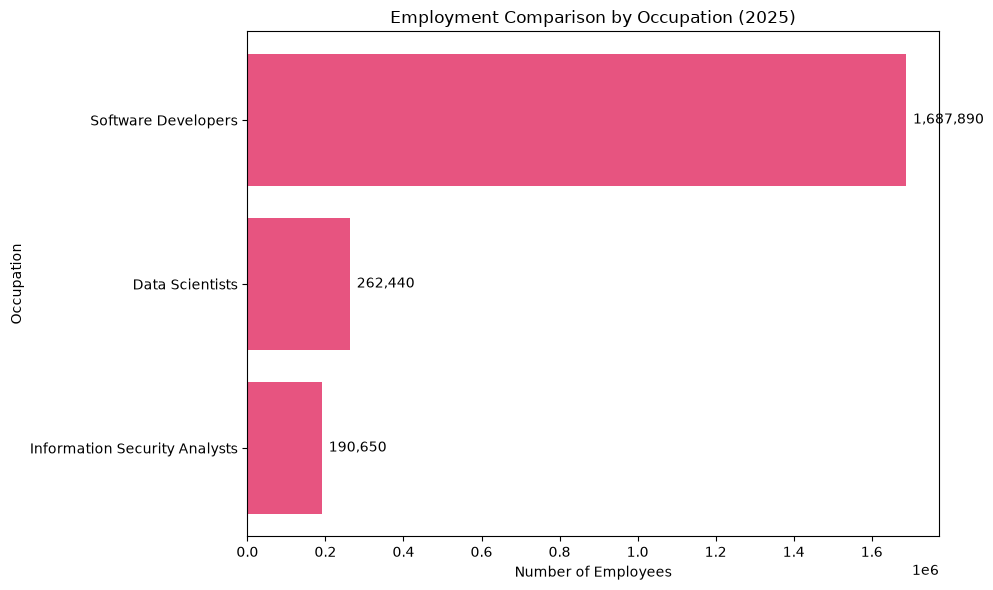

In [27]:
# Visualisation 2: Employment comparison by occupation in 2025

employment_2025 = comparison_df[
    comparison_df["Year"] == 2025
].copy()

employment_2025 = employment_2025.sort_values(
    by="Employment",
    ascending=True
)

plt.figure(figsize=(10, 6))

bars = plt.barh(
    employment_2025["Occupation"],
    employment_2025["Employment"],
    color="#E75480"
)

plt.bar_label(
    bars,
    labels=[
        f"{value:,.0f}"
        for value in employment_2025["Employment"]
    ],
    padding=5
)

plt.title("Employment Comparison by Occupation (2025)")
plt.xlabel("Number of Employees")
plt.ylabel("Occupation")

plt.tight_layout()
plt.show()

## Visualisation 3: Median Annual Wage Comparison (2022–2025)

### Objective
In general, all three professions saw an increase in wages from 2022 to 2025. Data Scientists saw the highest percentage rise in median yearly salaries, at roughly 16.16%, with Information Security Analysts at 15.34% and Software Developers at 6.85%.



### Visualisation Choice
A grouped bar chart was selected as it facilitates a side-by-side comparison of the median yearly earnings for various professions for each year. This simplifies the identification of variations among jobs and transformations over time.


### Findings
Software Developers had the greatest median yearly earnings in every year, rising from $127,260 in 2022 to $135,980 in 2025.
Information Security Analysts saw a rise from $112,000 to $129,180, whereas Data Scientists grew from $103,500 to $120,230.
In general, each of the three professions saw an increase in wages from 2022 to 2025. Information Security Analysts experienced the highest percentage growth during this timeframe.


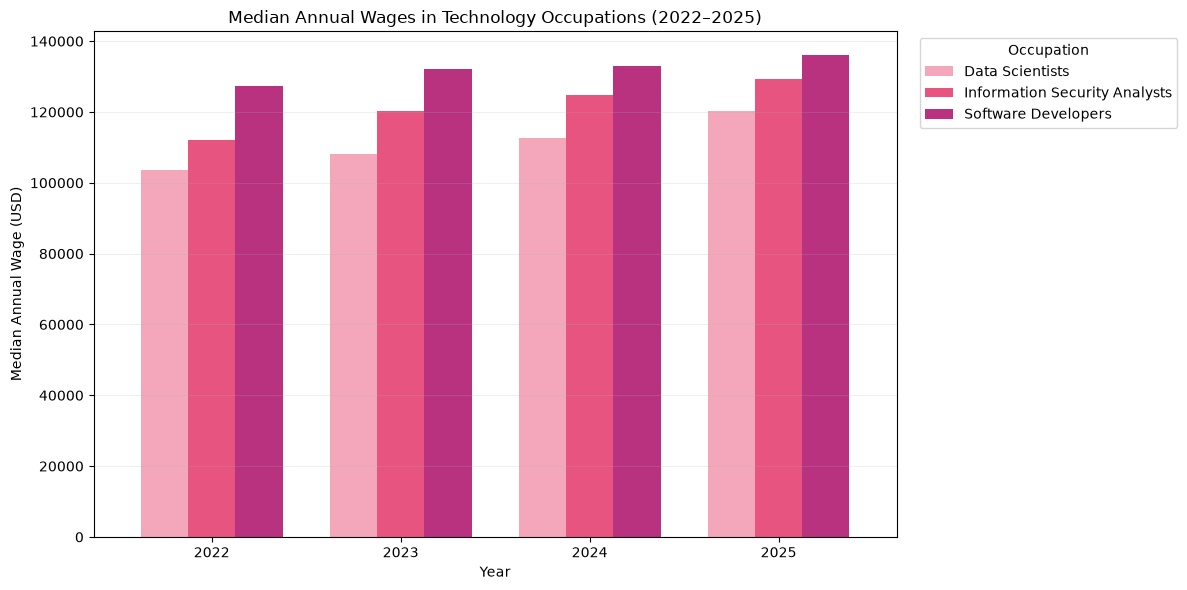

In [28]:
# Visualisation 3: Median annual wage comparison

wage_pivot = comparison_df.pivot(
    index="Year",
    columns="Occupation",
    values="Median_Annual_Wage"
)

# Pink colour palette
pink_colours = ["#F4A7BB", "#E75480", "#B83280"]

ax = wage_pivot.plot(
    kind="bar",
    figsize=(12, 6),
    color=pink_colours,
    width=0.75
)

plt.title("Median Annual Wages in Technology Occupations (2022–2025)")
plt.xlabel("Year")
plt.ylabel("Median Annual Wage (USD)")
plt.xticks(rotation=0)

plt.legend(
    title="Occupation",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

## Visualisation 4: Employment Distribution by Occupation (2025)

### Objective
This visualisation aims to explore the percentage of total employment contributed by each of the three chosen occupations in 2025.
### Visualisation choice
A pie chart was chosen as it demonstrates how different categories add up to a whole. It simplifies the understanding of relative employment shares.


### Findings
In 2025, Software Developers accounted for the highest percentage of jobs among the three professions. Data Scientists comprised the second-largest portion, whereas Information Security Analysts constituted the smallest portion.
This illustrates the variation in job distribution among the chosen technology professions.


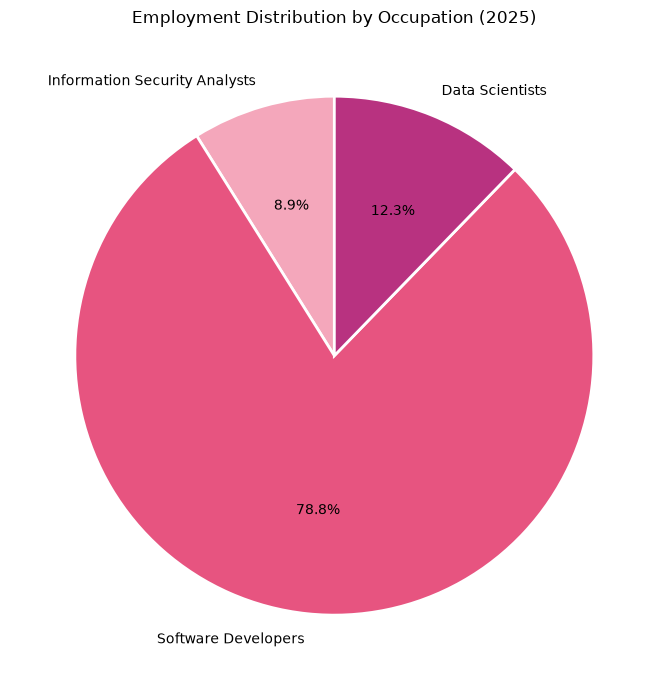

In [30]:
# Visualisation 4: Employment distribution in 2025

employment_2025 = comparison_df[
    comparison_df["Year"] == 2025
].copy()

plt.figure(figsize=(9, 7))

pink_colours = ["#F4A7BB", "#E75480", "#B83280"]

plt.pie(
    employment_2025["Employment"],
    labels=employment_2025["Occupation"],
    autopct="%1.1f%%",
    startangle=90,
    colors=pink_colours,
    wedgeprops={"edgecolor": "white", "linewidth": 2}
)

plt.title("Employment Distribution by Occupation (2025)")

plt.tight_layout()
plt.show()

## Visualisation 5: Relationship Between Employment and Median Annual Wages (2022–2025)

### Objective
This visualisation aims to explore the correlation between employment rates and median yearly salaries for the three chosen occupations over a span of four years.

### Visualisation choice
A scatter plot was chosen as it enables the comparison of two numerical variables. Employment appears on the horizontal axis while the median annual wage is located on the vertical axis. Various colors differentiate the professions.


### Findings
Software Developers consistently maintained the highest employment rates and comparatively high median yearly salaries. Information Security Analysts and Data Scientists experienced reduced employment rates yet showed strong median salaries.
The visualization indicates that a greater employment level does not automatically imply that a job has the highest median yearly salary.


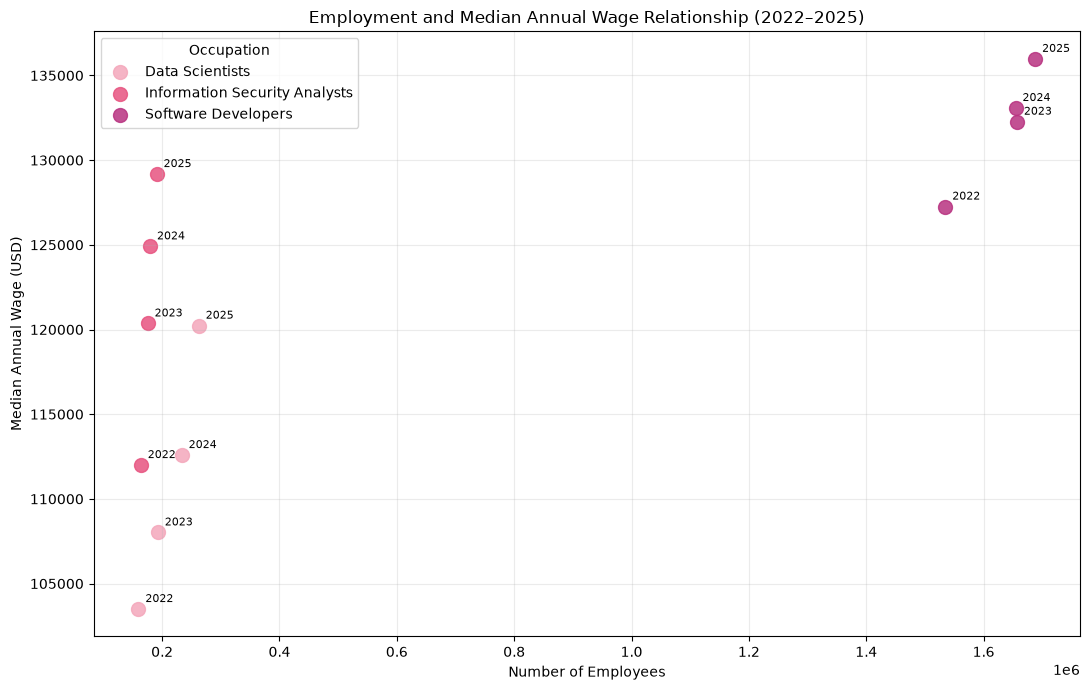

In [31]:
# Visualisation 5: Employment and wage relationship

plt.figure(figsize=(11, 7))

pink_colours = {
    "Information Security Analysts": "#E75480",
    "Software Developers": "#B83280",
    "Data Scientists": "#F4A7BB"
}

for occupation, group in comparison_df.groupby("Occupation"):

    plt.scatter(
        group["Employment"],
        group["Median_Annual_Wage"],
        label=occupation,
        color=pink_colours[occupation],
        s=100,
        alpha=0.85
    )

    # Label each point with its year
    for _, row in group.iterrows():
        plt.annotate(
            str(row["Year"]),
            (row["Employment"], row["Median_Annual_Wage"]),
            xytext=(5, 5),
            textcoords="offset points",
            fontsize=8
        )

plt.title("Employment and Median Annual Wage Relationship (2022–2025)")
plt.xlabel("Number of Employees")
plt.ylabel("Median Annual Wage (USD)")
plt.legend(title="Occupation")
plt.grid(True, alpha=0.25)
plt.tight_layout()
plt.show()

In [8]:
# Load the four BLS employment datasets

data_2022 = pd.read_excel("national_M2022_dl.xlsx")
data_2023 = pd.read_excel("all_data_M_2023.xlsx")
data_2024 = pd.read_excel("national_M2024_dl.xlsx")
data_2025 = pd.read_excel("national_M2025_dl.xlsx")

print("All four datasets loaded successfully!")

All four datasets loaded successfully!


In [8]:
# Check the size of each dataset

print("2022 dataset:", data_2022.shape)
print("2023 dataset:", data_2023.shape)
print("2024 dataset:", data_2024.shape)
print("2025 dataset:", data_2025.shape)

2022 dataset: (1402, 32)
2023 dataset: (413327, 32)
2024 dataset: (1403, 32)
2025 dataset: (1401, 32)


In [9]:
# Display the first five rows of the 2022 dataset

data_2022.head()

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,22.26,35.32,53.03,27340,33330,46310,73460,110290,NaN,NaN
1,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,51.62,78.71,106.03,50290,75350,107360,163710,220550,NaN,NaN
2,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,48.02,76.96,#,43440,62520,99890,160070,#,NaN,NaN
3,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,91.12,#,#,74920,122480,189520,#,#,NaN,NaN
4,99,U.S.,1,US,0,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,91.12,#,#,74920,122480,189520,#,#,NaN,NaN


In [10]:
# Display all column names

data_2022.columns.tolist()

['AREA',
 'AREA_TITLE',
 'AREA_TYPE',
 'PRIM_STATE',
 'NAICS',
 'NAICS_TITLE',
 'I_GROUP',
 'OWN_CODE',
 'OCC_CODE',
 'OCC_TITLE',
 'O_GROUP',
 'TOT_EMP',
 'EMP_PRSE',
 'JOBS_1000',
 'LOC_QUOTIENT',
 'PCT_TOTAL',
 'PCT_RPT',
 'H_MEAN',
 'A_MEAN',
 'MEAN_PRSE',
 'H_PCT10',
 'H_PCT25',
 'H_MEDIAN',
 'H_PCT75',
 'H_PCT90',
 'A_PCT10',
 'A_PCT25',
 'A_MEDIAN',
 'A_PCT75',
 'A_PCT90',
 'ANNUAL',
 'HOURLY']

In [11]:
# Identify the columns needed for our analysis

important_columns = [
    col for col in data_2022.columns
    if any(word in col for word in ["EMP", "MEDIAN", "MEAN", "OCC", "AREA", "NAICS", "OWN"])
]

print(important_columns)

['AREA', 'AREA_TITLE', 'AREA_TYPE', 'NAICS', 'NAICS_TITLE', 'OWN_CODE', 'OCC_CODE', 'OCC_TITLE', 'TOT_EMP', 'EMP_PRSE', 'H_MEAN', 'A_MEAN', 'MEAN_PRSE', 'H_MEDIAN', 'A_MEDIAN']


In [12]:
# Search for occupations related to AI and technology

data_2022[
    data_2022["OCC_TITLE"].str.contains(
        "Data Scientist|Software Developer|Information Security Analyst",
        case=False,
        na=False
    )
][["OCC_CODE", "OCC_TITLE"]]

,OCC_CODE,OCC_TITLE
136,15-1212,Information Security Analysts
149,15-1252,Software Developers
164,15-2050,Data Scientists
165,15-2051,Data Scientists


In [13]:
# Check the data types of important columns

data_2022[
    ["AREA", "NAICS", "OWN_CODE", "OCC_CODE",
     "OCC_TITLE", "TOT_EMP", "A_MEDIAN"]
].dtypes

AREA          int64
NAICS         int64
OWN_CODE      int64
OCC_CODE        str
OCC_TITLE       str
TOT_EMP       int64
A_MEDIAN     object
dtype: object

In [14]:
# Check the national employment records

data_2022[
    ["AREA", "AREA_TITLE", "NAICS", "OWN_CODE"]
].head()

,AREA,AREA_TITLE,NAICS,OWN_CODE
0,99,U.S.,0,1235
1,99,U.S.,0,1235
2,99,U.S.,0,1235
3,99,U.S.,0,1235
4,99,U.S.,0,1235


In [42]:
# Prepare the dashboard calculations

fastest_employment = employment_growth[
    "Growth_Percentage"
].idxmax()

highest_employment = comparison_df[
    comparison_df["Year"] == 2025
].loc[
    comparison_df[
        comparison_df["Year"] == 2025
    ]["Employment"].idxmax()
]

highest_wage = comparison_df[
    comparison_df["Year"] == 2025
].loc[
    comparison_df[
        comparison_df["Year"] == 2025
    ]["Median_Annual_Wage"].idxmax()
]

print("Fastest employment growth:", fastest_employment)
print("Highest employment in 2025:", highest_employment["Occupation"])
print("Highest median wage in 2025:", highest_wage["Occupation"])

Fastest employment growth: Data Scientists
Highest employment in 2025: Software Developers
Highest median wage in 2025: Software Developers


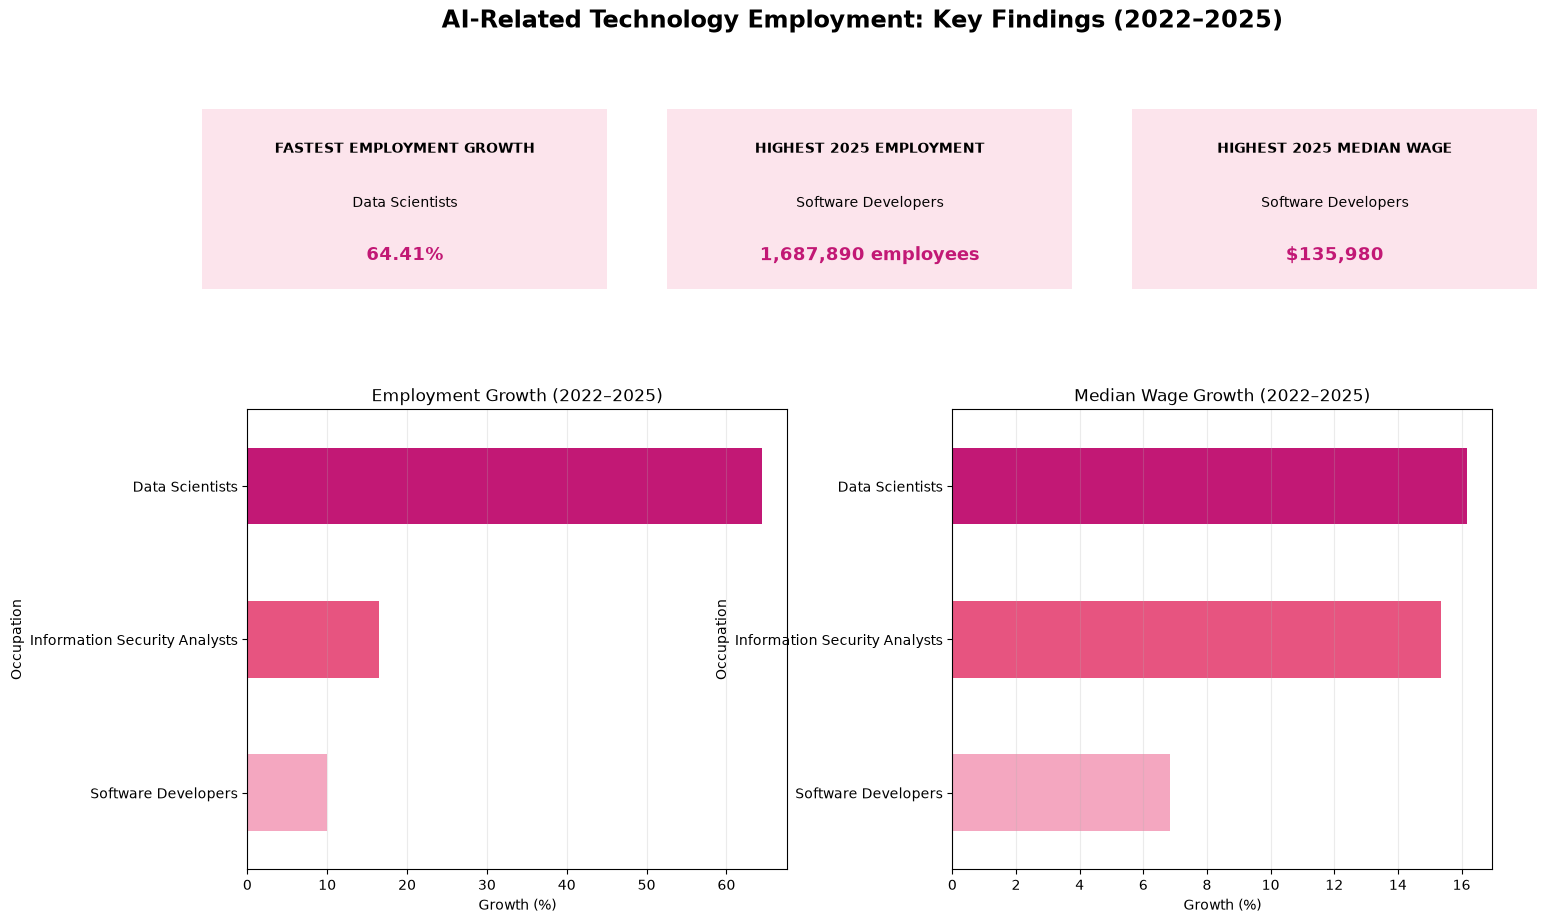

In [43]:
# KEY FINDINGS DASHBOARD: AI-RELATED TECHNOLOGY EMPLOYMENT

import matplotlib.pyplot as plt
import pandas as pd

# Identify the key findings
fastest_employment_growth = employment_growth[
    "Growth_Percentage"
].idxmax()

highest_employment = comparison_df[
    comparison_df["Year"] == 2025
].loc[lambda x: x["Employment"].idxmax()]

highest_wage = comparison_df[
    comparison_df["Year"] == 2025
].loc[lambda x: x["Median_Annual_Wage"].idxmax()]

# Create dashboard
fig = plt.figure(figsize=(15, 10))
fig.suptitle(
    "AI-Related Technology Employment: Key Findings (2022–2025)",
    fontsize=17,
    fontweight="bold",
    y=0.98
)

# KPI summary cards
kpis = [
    (
        "FASTEST EMPLOYMENT GROWTH",
        fastest_employment_growth,
        f"{employment_growth.loc[fastest_employment, 'Growth_Percentage']:.2f}%"
    ),
    (
        "HIGHEST 2025 EMPLOYMENT",
        highest_employment["Occupation"],
        f"{highest_employment['Employment']:,.0f} employees"
    ),
    (
        "HIGHEST 2025 MEDIAN WAGE",
        highest_wage["Occupation"],
        f"${highest_wage['Median_Annual_Wage']:,.0f}"
    )
]

for i, (title, occupation, value) in enumerate(kpis):
    ax = fig.add_axes([0.06 + i * 0.31, 0.70, 0.27, 0.18])
    ax.set_facecolor("#FCE4EC")
    ax.text(
        0.5, 0.78, title,
        ha="center", va="center",
        fontsize=10, fontweight="bold"
    )
    ax.text(
        0.5, 0.48, occupation,
        ha="center", va="center",
        fontsize=10, wrap=True
    )
    ax.text(
        0.5, 0.19, value,
        ha="center", va="center",
        fontsize=13, fontweight="bold",
        color="#C21875"
    )
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

# Employment growth chart
ax1 = fig.add_axes([0.09, 0.12, 0.36, 0.46])

employment_growth["Growth_Percentage"].sort_values().plot(
    kind="barh",
    ax=ax1,
    color=["#F4A7C0", "#E75480", "#C21875"]
)

ax1.set_title("Employment Growth (2022–2025)")
ax1.set_xlabel("Growth (%)")
ax1.set_ylabel("Occupation")
ax1.grid(axis="x", alpha=0.25)

# Wage growth chart
ax2 = fig.add_axes([0.56, 0.12, 0.36, 0.46])

wage_growth["Growth_Percentage"].sort_values().plot(
    kind="barh",
    ax=ax2,
    color=["#F4A7C0", "#E75480", "#C21875"]
)

ax2.set_title("Median Wage Growth (2022–2025)")
ax2.set_xlabel("Growth (%)")
ax2.set_ylabel("Occupation")
ax2.grid(axis="x", alpha=0.25)

plt.show()